---
title: "3.1 Өгөгдлийн анхдагч шинжилгээ"
---

Машин сургалтын загвар бүтээхээс өмнө өгөгдлөө сайн таньж мэдэх шаардлагатай. Өгөгдлийн анхдагч шинжилгээ (Exploratory Data Analysis, EDA) нь өгөгдлийн бүтэц, тархалт, дутуу болон аномаль утга, хувьсагчдын хоорондын хамаарлыг дүрслэлээр судлах үе шат юм.

:::{admonition} Энэ сэдвээр
:class: tip
- FORCE 2020 өгөгдлийн 15 цооногийн өгөгдлийг ачаалж, бүтэцтэй нь танилцана.
- Литологийн ангиудын тархалт, тэнцвэргүй байдлыг үнэлнэ.
- Каротажийн муруйнуудын статистик, хамаарлыг дүрслэлээр судална.
:::

## Шаардлагатай сангууд

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
import seaborn as sns

## 1. Өгөгдөл ачаалах

Энэ хичээлд FORCE 2020 тэмцээний өгөгдлөөс сонгосон Хойд тэнгисийн 15 цооногийг ашиглана. Үүнээс 14 цооногийг загвар сургахад (`SET = train`), 1 цооногийг (35/11-11) загварыг шалгахад (`SET = blind`) ашиглана. Шалгах цооногийг загвар сургалтын явцад огт ашиглахгүй.

In [2]:
DATA_URL = 'https://raw.githubusercontent.com/num-sgas/learn-num-sgas/main/courses/borehole-lithology/data/force_wells.csv.gz'
data = pd.read_csv(DATA_URL)
print(f'{data.shape[0]} мөр, {data.shape[1]} багана')

113982 мөр, 24 багана


In [3]:
data.head()

,WELL,DEPTH_MD,X_LOC,Y_LOC,Z_LOC,GROUP,FORMATION,CALI,RSHA,RMED,...,NPHI,PEF,DTC,SP,BS,DRHO,RXO,FORCE_2020_LITHOFACIES_LITHOLOGY,FORCE_2020_LITHOFACIES_CONFIDENCE,SET
0,16/10-2,2767.2652,443276.7812,6444984.5,-2740.0437,SHETLAND GP.,Svarte Fm.,NaN,NaN,5.3861,...,0.2880,65.1002,69.3440,99.6084,12.25,-0.8819,NaN,70000,2.0,train
1,16/10-2,2767.4172,443276.7812,6444984.5,-2740.1958,SHETLAND GP.,Svarte Fm.,NaN,NaN,4.4729,...,0.2891,56.3915,69.2193,100.2665,12.25,-0.9168,NaN,70000,2.0,train
2,16/10-2,2767.5692,443276.7812,6444984.5,-2740.3477,SHETLAND GP.,Svarte Fm.,NaN,NaN,4.3445,...,0.2969,42.3006,69.2900,100.4379,12.25,-0.9060,NaN,70000,2.0,train
3,16/10-2,2767.7212,443276.7812,6444984.5,-2740.4995,SHETLAND GP.,Svarte Fm.,NaN,NaN,4.8007,...,0.2988,47.0352,68.2213,100.3373,12.25,-0.9315,NaN,70000,2.0,train
4,16/10-2,2767.8732,443276.7812,6444984.5,-2740.6516,SHETLAND GP.,Svarte Fm.,NaN,NaN,4.7285,...,0.3116,94.4623,68.6381,100.1002,12.25,-0.9694,NaN,70000,2.0,train


## 2. Хувьсагчид

| Багана | Тайлбар | Нэгж |
|---|---|---|
| `WELL`, `SET` | Цооногийн нэр; сургалтын (`train`) эсвэл шалгах (`blind`) цооног | – |
| `DEPTH_MD` | Цооногийн дагуух гүн (measured depth) | м |
| `X_LOC`, `Y_LOC`, `Z_LOC` | Хэмжилтийн цэгийн координат | м |
| `GROUP`, `FORMATION` | Литостратиграфийн бүлэг, формаци | – |
| `GR` | Гамма | API |
| `CALI`, `BS` | Цооногийн диаметр (каверномер), өрмийн хошууны диаметр | инч |
| `RDEP`, `RMED`, `RSHA`, `RXO` | Гүн, дунд, гүехэн, зэргэлдээ бүсийн эсэргүүцэл | Ом·м |
| `RHOB`, `DRHO` | Нягт ба түүний засвар | г/см³ |
| `NPHI` | Нейтрон сүвшилт | д.н. |
| `PEF` | Фотоэлектрик эффект | б/э |
| `DTC` | Уртын долгионы хугацааны интервал | мкс/фут |
| `SP`, `SGR` | Өөрийн потенциал, спектрийн гамма | мВ, API |
| `FORCE_2020_LITHOFACIES_LITHOLOGY` | Литологийн код (зорилтот хувьсагч) | – |
| `FORCE_2020_LITHOFACIES_CONFIDENCE` | Тайллын итгэлцлийн түвшин (1 – өндөр, 3 – бага) | – |

## 3. Литологийн ангиуд

Литологийг 5 оронтой кодоор тэмдэглэсэн. Ойлгомжтой болгохын тулд код бүрт нэр, дүрслэлд ашиглах өнгө оноож, `LITH` багана нэмье:

In [4]:
LITHOLOGY = {
    30000: ('Элсэн чулуу',       '#F4D03F'),
    65030: ('Элсэн чулуу/Занар', '#E59866'),
    65000: ('Занар',             '#7F8C8D'),
    80000: ('Мергель',           '#76D7C4'),
    74000: ('Доломит',           '#AF7AC5'),
    70000: ('Шохойн чулуу',      '#3498DB'),
    70032: ('Цэрд',              '#AED6F1'),
    88000: ('Галит',             '#F5B7B1'),
    86000: ('Ангидрит',          '#C39BD3'),
    99000: ('Туф',               '#E74C3C'),
    90000: ('Нүүрс',             '#1C1C1C'),
    93000: ('Суурь чулуулаг',    '#6E2C00'),
}
LITH_NAMES  = {code: name  for code, (name, color) in LITHOLOGY.items()}
LITH_COLORS = {name: color for code, (name, color) in LITHOLOGY.items()}

data['LITH'] = data['FORCE_2020_LITHOFACIES_LITHOLOGY'].map(LITH_NAMES)

counts = pd.crosstab(data['LITH'], data['SET']).sort_values('train', ascending=False)
counts

SET,blind,train
LITH,,
Занар,7508,62173
Элсэн чулуу,1730,13944
Элсэн чулуу/Занар,2513,12190
Шохойн чулуу,496,6958
Мергель,467,4299
Туф,0,982
Цэрд,0,242
Нүүрс,124,170
Доломит,6,105


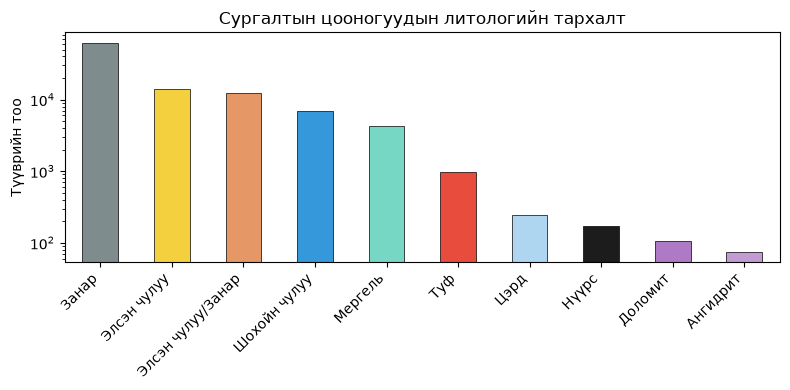

In [5]:
fig, ax = plt.subplots(figsize=(8, 4))
counts['train'].plot.bar(ax=ax, color=[LITH_COLORS[n] for n in counts.index], edgecolor='k', lw=0.5)
ax.set(ylabel='Түүврийн тоо', xlabel='', yscale='log',
       title='Сургалтын цооногуудын литологийн тархалт')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

Босоо тэнхлэг логарифм хуваарьтай гэдгийг анхаараарай: занар бусад ангиас хэдэн арав дахин олон байна.

**Асуулт 1:**  
Ангиудын тоо ийм тэнцвэргүй байх нь машин сургалтын загварт ямар нөлөө үзүүлэх вэ?

:::{dropdown} Хариулт
Загвар олон түүвэртэй анги (занар) руу хэлбийх хандлагатай болно. Жишээ нь бүх түүврийг "занар" гэж таамагласан ч нийт нарийвчлал 60 гаруй хувьтай гарна. Гэтэл цөөн түүвэртэй ангиудыг (ангидрит, доломит, нүүрс) загвар бараг сурч чадахгүй. Энэ асуудлыг 3.5-р сэдэвт ангиудыг тэнцвэржүүлэх (SMOTE) аргаар шийдвэрлэнэ.
:::

In [6]:
pd.crosstab(data['WELL'], data['LITH'])

LITH,Ангидрит,Доломит,Занар,Мергель,Нүүрс,Туф,Цэрд,Шохойн чулуу,Элсэн чулуу,Элсэн чулуу/Занар
WELL,,,,,,,,,,
16/10-2,0,0,380,189,0,0,18,132,958,760
16/10-5,0,0,1195,174,0,0,2,667,543,184
16/2-16,75,0,5810,1118,0,170,0,1277,1311,264
16/2-6,0,94,4794,1094,0,123,0,1261,1429,343
16/5-3,0,0,461,428,0,0,222,1520,274,116
25/11-19 S,0,0,5569,0,0,376,0,191,802,37
31/2-19 S,0,0,11595,663,86,0,0,273,2183,1655
31/2-9,0,0,6182,0,0,260,0,199,857,1201
32/2-1,0,0,1659,0,0,0,0,15,1036,339


## 4. Давхардсан мөр

Давхардсан мөр байвал загвар зарим түүврийг илүү "чухал" гэж үзэх тул устгах хэрэгтэй:

In [7]:
n_before = len(data)
data = data.drop_duplicates(ignore_index=True)
print(f'Устгасан давхардсан мөр: {n_before - len(data)}')

Устгасан давхардсан мөр: 0


## 5. Статистик үзүүлэлт

Загварт ашиглах 8 муруйн статистик үзүүлэлтийг харъя:

In [8]:
FEATURES = ['GR', 'RHOB', 'NPHI', 'RDEP', 'RMED', 'DTC', 'PEF', 'CALI']
data[FEATURES].describe().round(2).T

,count,mean,std,min,25%,50%,75%,max
GR,113982.0,85.41,42.56,6.51,57.15,80.96,103.91,726.27
RHOB,112366.0,2.33,0.23,1.31,2.15,2.36,2.52,3.16
NPHI,112741.0,0.34,0.11,0.00,0.27,0.34,0.43,0.99
RDEP,113923.0,3.76,13.16,0.12,1.08,1.68,2.99,1596.29
RMED,113412.0,3.88,17.98,0.13,1.06,1.68,2.96,1950.00
DTC,112720.0,109.73,28.52,43.76,84.37,104.88,136.49,208.56
PEF,112382.0,5.27,5.99,0.10,3.41,3.95,5.08,353.28
CALI,113276.0,10.96,2.72,6.01,8.57,10.80,12.57,22.68


Хамгийн их утгуудыг анхаараарай: GR 726 API, PEF 353 б/э, RDEP 1596 Ом·м хүрч байна. Эдгээр нь ихэвчлэн хэмжилтийн алдаа эсвэл цооногийн нөхцөлөөс үүдсэн **аномаль утга** бөгөөд 3.2-р сэдэвт судална.

**Асуулт 2:**  
RDEP-ийн дундаж (3.76) нь медианаас (1.68) хоёр дахин их байна. Энэ нь юуг илтгэж байна вэ?

:::{dropdown} Хариулт
Тархалт баруун тийш хүчтэй хазгай: ихэнх утга бага боловч цөөн тооны маш өндөр утга (нягт шохойн чулуу, нүүрс, ангидрит, мөн аномаль утга) дунджийг өсгөж байна. Иймд эсэргүүцлийг логарифм хуваарьт дүрсэлдэг ба загварт оруулахдаа логарифм хувиргалт хийнэ (3.4-р сэдэв).
:::

In [9]:
coverage = data.groupby('WELL')[FEATURES].apply(lambda d: d.notna().mean() * 100).round(0)
coverage

,GR,RHOB,NPHI,RDEP,RMED,DTC,PEF,CALI
WELL,,,,,,,,
16/10-2,100.0,100.0,100.0,100.0,100.0,100.0,100.0,99.0
16/10-5,100.0,94.0,96.0,100.0,100.0,96.0,94.0,97.0
16/2-16,100.0,97.0,99.0,100.0,100.0,99.0,97.0,100.0
16/2-6,100.0,97.0,98.0,100.0,100.0,97.0,97.0,98.0
16/5-3,100.0,99.0,99.0,100.0,100.0,100.0,99.0,100.0
25/11-19 S,100.0,100.0,100.0,100.0,100.0,99.0,100.0,100.0
31/2-19 S,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0
31/2-9,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0
32/2-1,100.0,97.0,98.0,100.0,97.0,95.0,97.0,99.0


Хүснэгтэд муруй бүрийн бүртгэгдсэн интервалын хувийг үзүүлэв. Зарим цооногт RHOB, NPHI, DTC, PEF муруйн 3–6% нь бүртгэгдээгүй байна. Үүнийг 3.3-р сэдэвт нөхнө.

## 6. Каротажийн диаграм

Муруйнуудыг литологийн тайлалтай нь хамт гүнээр дүрсэлье:

In [10]:
def plot_well(df, well):
    d = df[df['WELL'] == well].sort_values('DEPTH_MD')
    depth = d['DEPTH_MD']
    fig, axes = plt.subplots(1, 6, figsize=(12, 9), sharey=True,
                             gridspec_kw={'width_ratios': [1, 1, 1, 1, 1, 0.5]})

    ax = axes[0]
    ax.plot(d['GR'], depth, color='green', lw=0.6)
    ax.set(xlim=(0, 150), xlabel='GR (API)')

    ax = axes[1]
    ax.plot(d['CALI'], depth, color='k', lw=0.6, label='CALI')
    ax.plot(d['BS'], depth, color='grey', ls='--', lw=0.8, label='BS')
    ax.set(xlim=(6, 20), xlabel='CALI, BS (инч)')
    ax.legend(loc='lower right', fontsize=8)

    ax = axes[2]
    ax.plot(d['RDEP'], depth, color='red', lw=0.6, label='RDEP')
    ax.plot(d['RMED'], depth, color='blue', lw=0.6, label='RMED')
    ax.set(xscale='log', xlim=(0.2, 200), xlabel='Эсэргүүцэл (Ом·м)')
    ax.legend(loc='lower right', fontsize=8)

    ax = axes[3]
    ax.plot(d['RHOB'], depth, color='red', lw=0.6)
    ax.set(xlim=(1.95, 2.95), xlabel='RHOB (г/см³)')
    ax2 = ax.twiny()
    ax2.plot(d['NPHI'], depth, color='blue', lw=0.6)
    ax2.set_xlim(0.45, -0.15)
    ax2.set_xlabel('NPHI (д.н.)', color='blue')

    ax = axes[4]
    ax.plot(d['DTC'], depth, color='purple', lw=0.6)
    ax.set(xlim=(140, 40), xlabel='DTC (мкс/фут)')

    ax = axes[5]
    codes = list(LITHOLOGY.keys())
    index = d['FORCE_2020_LITHOFACIES_LITHOLOGY'].map({c: i for i, c in enumerate(codes)}).to_numpy()
    cmap = ListedColormap([LITHOLOGY[c][1] for c in codes])
    ax.imshow(index[:, None], aspect='auto', cmap=cmap, vmin=0, vmax=len(codes) - 1,
              interpolation='none', extent=(0, 1, depth.max(), depth.min()))
    ax.set(xticks=[], xlabel='Литологи')

    for a in axes[:5]:
        a.grid(alpha=0.3)
    axes[0].set_ylabel('Гүн, MD (м)')
    axes[0].set_ylim(depth.max(), depth.min())
    fig.suptitle(well, fontweight='bold')
    plt.tight_layout()
    plt.show()

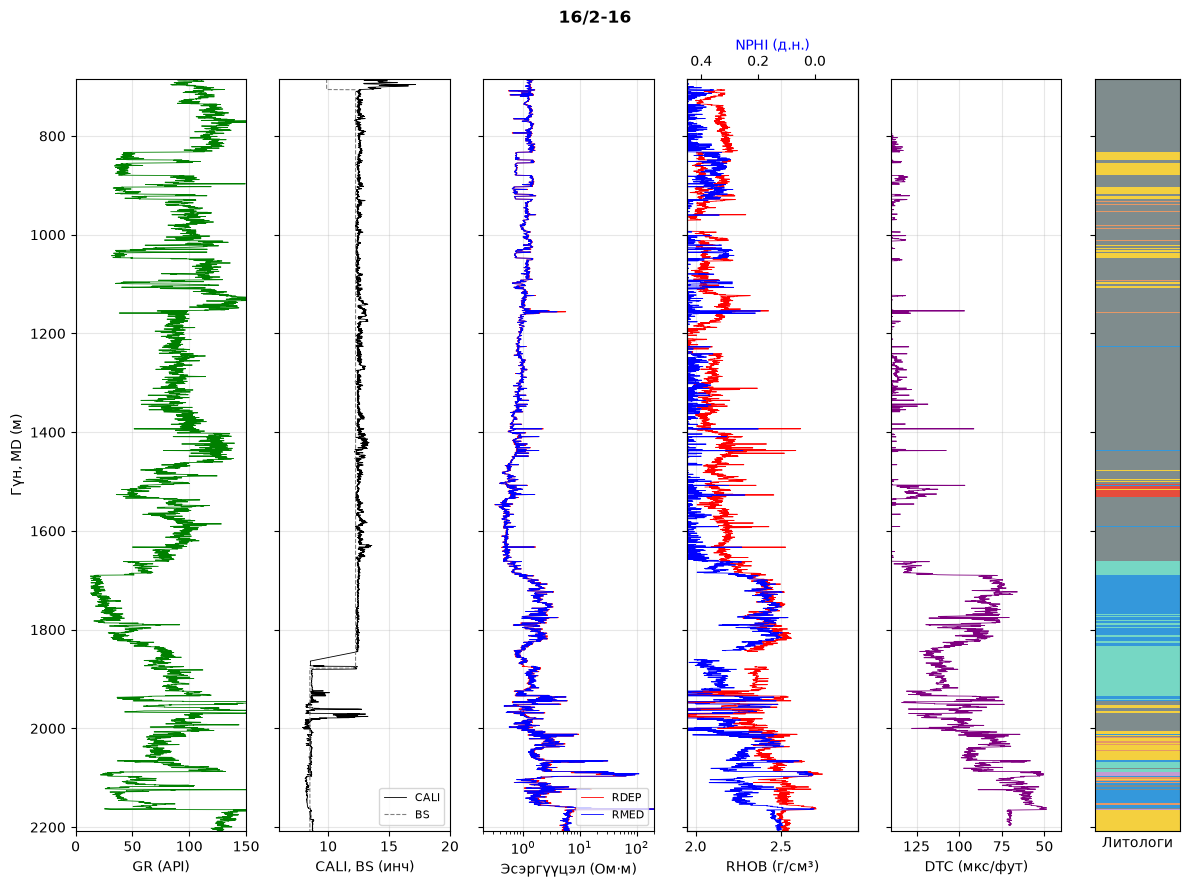

In [11]:
plot_well(data, '16/2-16')

**Дасгал:** `plot_well` функцийг өөр цооног дээр ажиллуулж үзээрэй, жишээ нь `'31/2-19 S'` эсвэл `'16/5-3'`. Шохойн чулуу (цэнхэр) болон элсэн чулуу (шар) давхаргуудад муруйнууд хэрхэн өөрчлөгдөж байна вэ?

## 7. Муруйнуудын хоорондын хамаарал

Хоёр муруйн хоорондох хамаарлыг цэгэн диаграмаар харуулна. Дүрслэлийг тодорхой болгохын тулд:
- 20 000 түүврийг санамсаргүйгээр сонгоно;
- **зөвхөн дүрслэлд** 1–99-р перцентилийн гадна орших утгуудыг хасна (өгөгдөл өөрчлөгдөхгүй);
- эсэргүүцлийг логарифм хэлбэрээр (`log10(RDEP)`) харуулна.

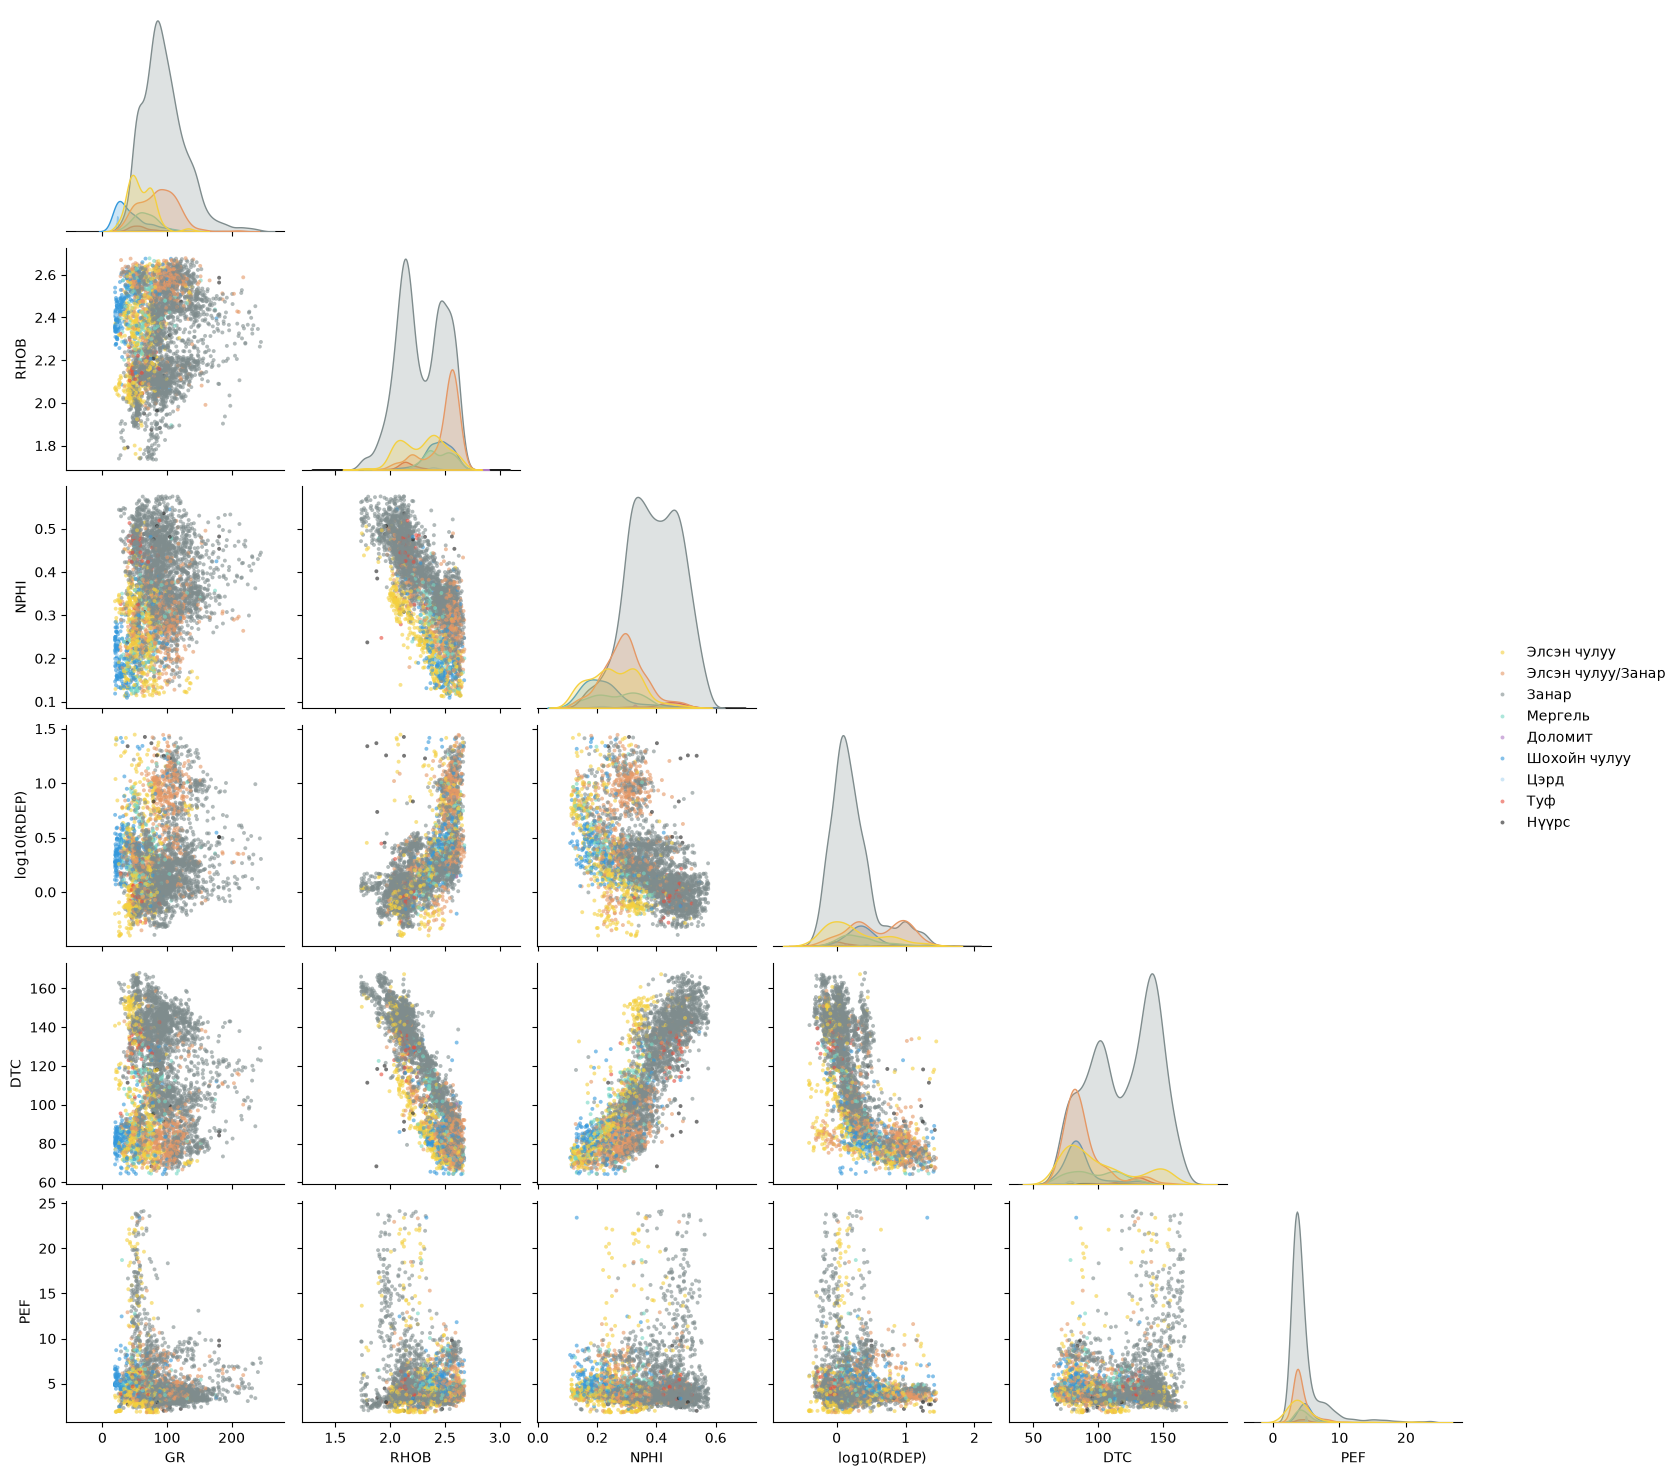

In [12]:
cols = ['GR', 'RHOB', 'NPHI', 'log10(RDEP)', 'DTC', 'PEF']

sample = data.dropna(subset=FEATURES).sample(20000, random_state=42).copy()
sample['log10(RDEP)'] = np.log10(sample['RDEP'])
low, high = sample[cols].quantile(0.01), sample[cols].quantile(0.99)
sample = sample[((sample[cols] >= low) & (sample[cols] <= high)).all(axis=1)]
order = [n for n in LITH_COLORS if n in sample['LITH'].unique()]

g = sns.pairplot(sample.sample(4000, random_state=42)[cols + ['LITH']],
                 hue='LITH', hue_order=order, palette=LITH_COLORS, corner=True,
                 diag_kind='kde', plot_kws={'s': 8, 'alpha': 0.6, 'edgecolor': 'none'})
g._legend.set_title('')
plt.show()

**Асуулт 3:**  
Аль муруй шохойн чулууг (цэнхэр) элсэн чулуунаас (шар) хамгийн сайн ялгаж байна вэ?

:::{dropdown} Хариулт
**PEF**: шохойн чулууны PEF ойролцоогоор 5 б/э, элсэн чулууных 2 орчим байдаг. Мөн RHOB–NPHI диаграм дээр шохойн чулуу нягт өндөр, нейтрон сүвшилт бага хэсэгт байрлана. Ийм физик ялгаа нь литологийг машин сургалтаар тайлах боломжийг олгодог.
:::

## 8. Литологи тус бүрийн муруйн утгын тархалт

Муруйн утга тус бүрд аль литологи давамгайлж байгааг харуулъя. Диаграмын босоо тэнхлэг нь тухайн утгад литологи бүрийн эзлэх хувь юм:

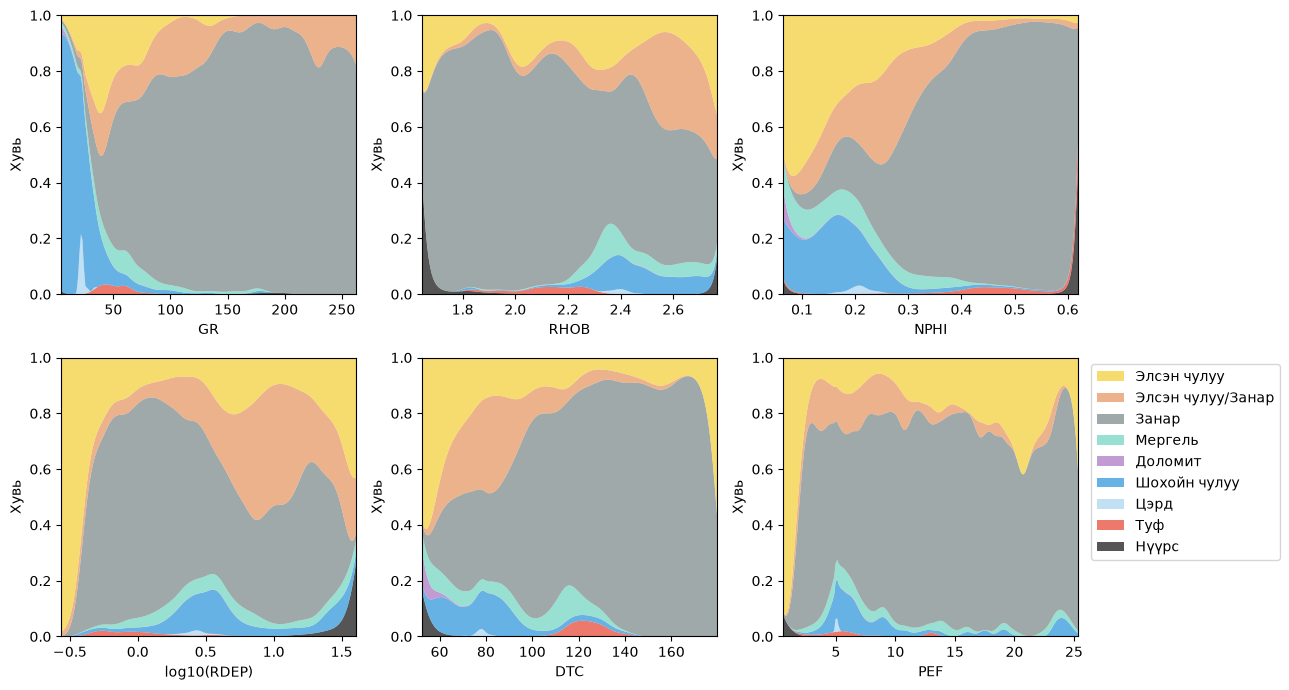

In [13]:
fig, axes = plt.subplots(2, 3, figsize=(13, 7))
for ax, col in zip(axes.flat, cols):
    sns.kdeplot(data=sample, x=col, hue='LITH', hue_order=order, palette=LITH_COLORS,
                multiple='fill', linewidth=0, ax=ax, legend=(col == cols[-1]))
    ax.set(ylabel='Хувь', xlabel=col)
sns.move_legend(axes.flat[-1], 'upper left', bbox_to_anchor=(1.02, 1), title='')
plt.tight_layout()
plt.show()

## 9. Үр дүнг хадгалах

`LITH` багана нэмэгдсэн өгөгдлийг дараагийн сэдэвт ашиглахаар хадгална:

In [14]:
data.to_csv('../data/after-3-1.csv.gz', index=False, float_format='%.4f')

## Дүгнэлт

- Сургалтын өгөгдөл 14 цооногийн 101 мянга орчим түүвэртэй бөгөөд занар давамгайлсан, тэнцвэргүй.
- Зарим муруйд аномаль утга (3.2-р сэдэв) болон бүртгэгдээгүй интервал (3.3-р сэдэв) байна.
- PEF, RHOB, NPHI, DTC зэрэг муруйнууд литологийг ялгах физик ялгаатай.

**Дараагийн сэдэв:** 3.2 Аномаль утга

:::{admonition} Эх сурвалж
:class: seealso
Өгөгдөл: Bormann P., Aursand P., Dilib F., Manral S., Dischington P. (2020). *FORCE 2020 Well well log and lithofacies dataset for machine learning competition*. Zenodo. [doi:10.5281/zenodo.4351156](https://doi.org/10.5281/zenodo.4351156). Каротажийн өгөгдөл [NLOD 2.0](https://data.norge.no/nlod/en/2.0), литологийн тайлал [CC BY 4.0](https://creativecommons.org/licenses/by/4.0/) лицензтэй.

Шинжилгээний арга нь Hall (2016) *Facies classification using machine learning* (The Leading Edge, 35(10), 906–909) болон Andy McDonald-ийн notebook-уудаас санаа авсан.
:::